Joonseo Bang & Khevin Jae Feliciano

Background information : This comprehensive synthetic dataset models the rapidly evolving Indian Food Delivery and Quick-Commerce Ecosystem across 2025–2026. Featuring 1,000,000 unique order records and 22 granular columns, it captures customer demographics, regional micro-markets, platform market share (Zomato, Swiggy, Blinkit Cafe, Zepto Cafe, Eatsure, etc.), unit economics, logistics bottlenecks, and customer satisfaction metrics.

Source link : https://www.kaggle.com/datasets/aryansingh2000/food-delivery-in-india

## Import library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,       # Split data into train/test sets
    cross_val_score         # Cross-validation for robust evaluation
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

## Create dataset

In [ ]:
import pandas as pd
import numpy as np

# Load a manageable chunk of the actual Food Delivery dataset
file_path = '/content/indian_food_delivery_sales_and_customer_insights_1m.csv'

# Reading 5,000 rows to create a quick, applicable subset
df_raw = pd.read_csv(file_path, nrows=5000)

# Standardize column names to lowercase to make mapping easier
df_raw.columns = [col.lower().strip() for col in df_raw.columns]

print("Available columns in dataset:")
print(list(df_raw.columns))
print()

# Dynamically select appropriate features based on columns present in the dataset
feature_candidates = {
    'order_amount': ['order_value', 'order_amount', 'amount_spent', 'total_amount', 'amount'],
    'delivery_time_mins': ['delivery_time_mins', 'delivery_time', 'time_taken'],
    'customer_rating': ['customer_rating', 'rating', 'order_rating'],
    'distance_km': ['distance_km', 'distance', 'distance_travelled'],
    'discount_amount': ['discount_amount', 'discount', 'discount_value']
}

features = []
for key, candidates in feature_candidates.items():
    matched = False
    for c in candidates:
        if c in df_raw.columns:
            features.append(c)
            matched = True
            break
    if not matched:
        for col in df_raw.select_dtypes(include=[np.number]).columns:
            if col not in features and 'id' not in col and col != 'age':
                features.append(col)
                break

# Determine the target variable
target_candidates = ['customer_segmentation', 'segmentation', 'rating_category', 'member_type']
target = None
for c in target_candidates:
    if c in df_raw.columns:
        target = c
        break

if not target:
    for col in df_raw.select_dtypes(exclude=[np.number]).columns:
        if 'id' not in col and df_raw[col].nunique() <= 10:
            target = col
            break

print(f"Selected Features: {features}")
print(f"Selected Target:   {target}")
print()

# Process the dataset
df = df_raw[features + [target]].dropna().copy()

# Quick look at the actual dataset
print("STEP 2: Food Delivery Dataset Overview")
print("-" * 40)
print(f"Total samples:       {df.shape[0]}")
print(f"Number of features:  {len(features)}")
print(f"Number of classes:   {df[target].nunique()}")
print()

print("Class distribution:")
print(df[target].value_counts().to_string())
print()

print("First 5 rows of the processed dataset:")
print(df.head().to_string(index=False))

Available columns in dataset:
['order_id', 'first_name', 'last_name', 'age', 'gender', 'city', 'state', 'pincode', 'delivery_platform', 'cuisine_preference', 'meal_slot', 'is_pro_subscriber', 'food_bill_inr', 'discount_applied_inr', 'delivery_fee_inr', 'gross_order_value_inr', 'platform_net_profit_inr', 'payment_method', 'delivery_time_mins', 'customer_rating', 'is_order_cancelled', 'order_timestamp']

Selected Features: ['pincode', 'delivery_time_mins', 'customer_rating', 'food_bill_inr', 'discount_applied_inr']
Selected Target:   gender

STEP 2: Food Delivery Dataset Overview
----------------------------------------
Total samples:       5000
Number of features:  5
Number of classes:   3

Class distribution:
gender
Male      2789
Female    2124
Other       87

First 5 rows of the processed dataset:
 pincode  delivery_time_mins  customer_rating  food_bill_inr  discount_applied_inr gender
  564428                  16                5         888.99                131.00   Male
  516469 

## Explore data

Average measurements per gender group:
           pincode  delivery_time_mins  customer_rating  food_bill_inr  \
gender                                                                   
Female  482936.281              38.253            3.983        950.768   
Male    479845.148              38.046            3.989        956.992   
Other   473685.241              38.678            3.989        965.093   

        discount_applied_inr  
gender                        
Female               143.124  
Male                 140.176  
Other                138.386  



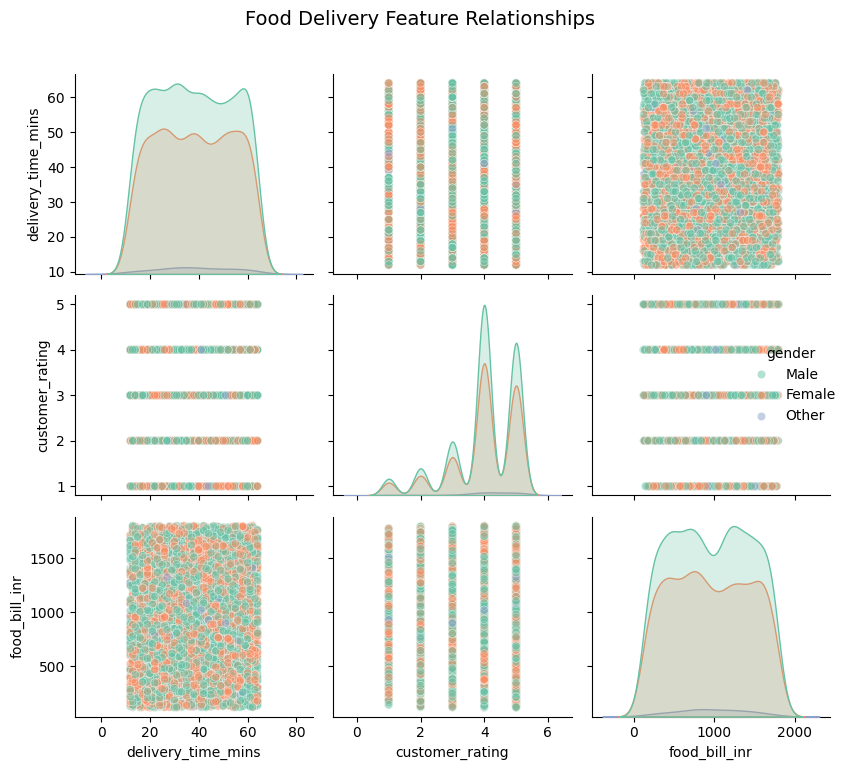

   -> Pair plot saved as 'food_delivery_pairplot.png'
   -> Look for features where the classes separate well.



/tmp/ipykernel_575/1701653885.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


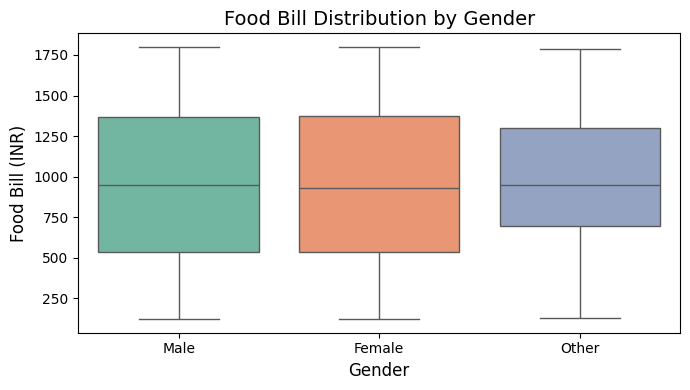

   -> Box plot saved as 'food_bill_boxplot.png'



In [ ]:
# Average values for each gender group
print("Average measurements per gender group:")
print(df.groupby('gender').mean().round(3))
print()

# --- Pair Plot ---
# We pick a subset of numerical columns plus 'gender' as the hue
plot_features = ['delivery_time_mins', 'customer_rating', 'food_bill_inr', 'gender']

sns.pairplot(
    df[plot_features],
    hue='gender',
    palette='Set2',
    diag_kind='kde',
    plot_kws={
        'alpha': 0.5,
        'edgecolor': 'w'
    }
)
plt.suptitle('Food Delivery Feature Relationships', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig('food_delivery_pairplot.png', dpi=150)
plt.show()

print("   -> Pair plot saved as 'food_delivery_pairplot.png'")
print("   -> Look for features where the classes separate well.")
print()

# --- Individual feature comparison ---
# Let's make a box plot for food_bill_inr by gender
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df,
    x='gender',
    y='food_bill_inr',
    palette='Set2'
)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Food Bill (INR)', fontsize=12)
plt.title('Food Bill Distribution by Gender', fontsize=14)
plt.tight_layout()
plt.savefig('food_bill_boxplot.png', dpi=150)
plt.show()

print("   -> Box plot saved as 'food_bill_boxplot.png'")
print()

## Prepare data

In [ ]:
# Separate features from labels dynamically using the defined target
X = df.drop(target, axis=1)    # All columns except the target
y = df[target]                 # Just the target column

# Split: 80% training, 20% testing
# stratify=y ensures each target class is proportionally represented
# in both the training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")
print()

# Verify the class balance in both sets
print("Class balance check:")
print(f"  Training: {dict(y_train.value_counts())}")
print(f"  Testing:  {dict(y_test.value_counts())}")
print("  (Should be roughly proportional)")
print()

# Scale features
# Remember: fit_transform on training, transform on testing!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # Learn + scale
X_test_scaled  = scaler.transform(X_test)         # Scale only (no learning)

print("Features scaled with StandardScaler.")
print()

Training samples: 4000
Testing samples:  1000

Class balance check:
  Training: {'Male': np.int64(2231), 'Female': np.int64(1699), 'Other': np.int64(70)}
  Testing:  {'Male': np.int64(558), 'Female': np.int64(425), 'Other': np.int64(17)}
  (Should be roughly proportional)

Features scaled with StandardScaler.



## Train & evaluate model

Overall Accuracy: 51.00%

Classification Report:
              precision    recall  f1-score   support

      Female       0.43      0.38      0.40       425
        Male       0.56      0.63      0.59       558
       Other       0.00      0.00      0.00        17

    accuracy                           0.51      1000
   macro avg       0.33      0.33      0.33      1000
weighted avg       0.49      0.51      0.50      1000



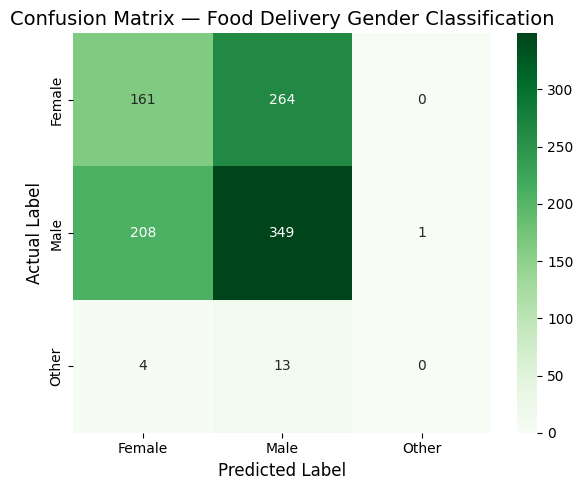

   -> Confusion matrix saved as 'food_delivery_confusion.png'



In [ ]:
# Create and train the model
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# --- Accuracy ---
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {accuracy:.2%}")
print()

# --- Classification Report ---
print("Classification Report:")
print(classification_report(y_test, y_pred))

# --- Confusion Matrix ---
# Dynamically read unique labels present in the target variable
labels_order = sorted(list(y_train.unique()))
cm = confusion_matrix(
    y_test, y_pred,
    labels=labels_order
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,                                    # Show numbers
    fmt='d',                                       # Integer format
    cmap='Greens',                                 # Green color scheme
    xticklabels=labels_order,                      # Predicted labels
    yticklabels=labels_order                       # Actual labels
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix — Food Delivery Gender Classification', fontsize=14)
plt.tight_layout()
plt.savefig('food_delivery_confusion.png', dpi=150)
plt.show()

print("   -> Confusion matrix saved as 'food_delivery_confusion.png'")
print()

## Find best k using cross-validation

   K= 1 → CV Accuracy = 48.55% (±1.54%)
   K= 5 → CV Accuracy = 50.15% (±0.97%)
   K=10 → CV Accuracy = 49.53% (±1.28%)
   K=15 → CV Accuracy = 52.10% (±2.07%)
   K=20 → CV Accuracy = 50.50% (±2.03%)
   K=25 → CV Accuracy = 51.88% (±1.88%)
   K=30 → CV Accuracy = 51.88% (±1.64%)



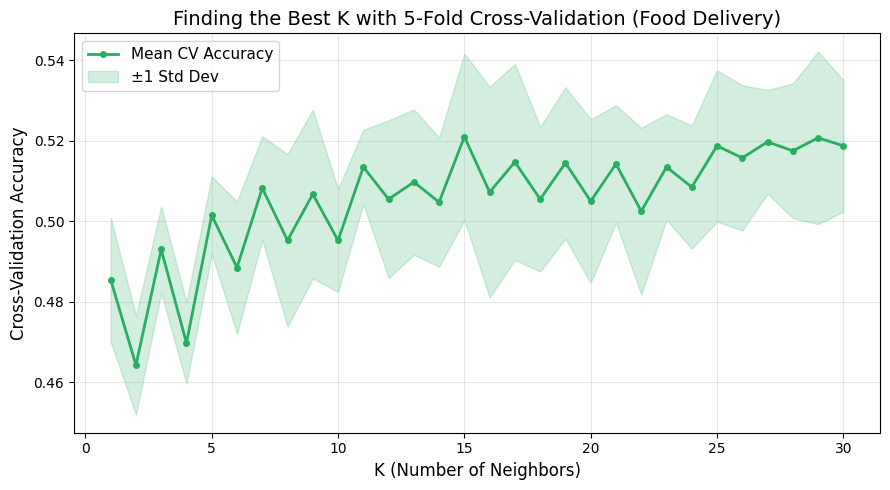

   -> Best K = 15
   -> Best CV Accuracy = 52.10%
   -> Chart saved as 'food_delivery_best_k.png'



In [ ]:
# Test K from 1 to 30
k_range = range(1, 31)

# For each K, we'll store:
#   - The mean CV accuracy (average across 5 folds)
#   - The std of CV accuracy (how much it varies between folds)
cv_means = []    # Average accuracy
cv_stds = []     # Standard deviation (spread)

for k in k_range:
    # Create a model with this K
    model = KNeighborsClassifier(n_neighbors=k)

    # Run 5-fold cross-validation on the TRAINING data only
    # cross_val_score returns an array of 5 accuracy scores
    scores = cross_val_score(
        model,                   # The model to evaluate
        X_train_scaled,          # The training features (scaled)
        y_train,                 # The training labels
        cv=5,                    # 5 folds
        scoring='accuracy'       # Metric to use
    )

    # Store the mean and standard deviation
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

    # Print progress every 5 steps
    if k % 5 == 0 or k == 1:
        print(f"   K={k:2d} → CV Accuracy = {scores.mean():.2%} (±{scores.std():.2%})")

print()

# --- Plot the results ---
# We plot the mean accuracy as a line and add a shaded region
# showing ± 1 standard deviation (the uncertainty band)
plt.figure(figsize=(9, 5))

# Convert to numpy arrays for easy math
cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)
k_list = list(k_range)

# Main line (mean accuracy)
plt.plot(k_list, cv_means, marker='o', color='#27ae60',
         linewidth=2, markersize=4, label='Mean CV Accuracy')

# Shaded region (±1 standard deviation)
# This shows the UNCERTAINTY in our accuracy estimate
plt.fill_between(
    k_list,
    cv_means - cv_stds,     # Lower bound
    cv_means + cv_stds,     # Upper bound
    alpha=0.2,              # Transparency
    color='#27ae60',        # Same green
    label='±1 Std Dev'
)

plt.xlabel('K (Number of Neighbors)', fontsize=12)
plt.ylabel('Cross-Validation Accuracy', fontsize=12)
plt.title('Finding the Best K with 5-Fold Cross-Validation (Food Delivery)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('food_delivery_best_k.png', dpi=150)
plt.show()

# Find the best K
best_k = k_list[np.argmax(cv_means)]
best_cv_accuracy = cv_means.max()

print(f"   -> Best K = {best_k}")
print(f"   -> Best CV Accuracy = {best_cv_accuracy:.2%}")
print(f"   -> Chart saved as 'food_delivery_best_k.png'")
print()

## Retrain with best k and evaluate on test set

In [ ]:
# Retrain with the best K
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

# Final predictions on the test set
y_pred_final = final_model.predict(X_test_scaled)

# Final accuracy
final_accuracy = accuracy_score(y_test, y_pred_final)
print(f"Final Test Accuracy (K={best_k}): {final_accuracy:.2%}")
print()

# Final classification report
print("Final Classification Report:")
print(classification_report(y_test, y_pred_final))

Final Test Accuracy (K=15): 51.20%

Final Classification Report:
              precision    recall  f1-score   support

      Female       0.42      0.32      0.36       425
        Male       0.56      0.67      0.61       558
       Other       0.00      0.00      0.00        17

    accuracy                           0.51      1000
   macro avg       0.33      0.33      0.32      1000
weighted avg       0.49      0.51      0.49      1000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Predict

In [ ]:
# Three new customers with different order characteristics
new_customers = pd.DataFrame({
    'pincode':              [564428,  384832,  163239],
    'delivery_time_mins':   [15,      45,      30],
    'customer_rating':      [5,       2,       4],
    'food_bill_inr':        [450.00,  1500.50, 850.25],
    'discount_applied_inr': [50.00,   300.00,  85.00]
})

print("New customer transaction metrics:")
print(new_customers.to_string(index=False))
print()

# IMPORTANT: Scale using the SAME scaler fit on training data
# (Never create a new StandardScaler for new data!)
new_scaled = scaler.transform(new_customers)

# Get predictions and probabilities
predictions = final_model.predict(new_scaled)
probabilities = final_model.predict_proba(new_scaled)

# Display results for each customer
class_labels = final_model.classes_

for i in range(len(new_customers)):
    print(f"Customer #{i+1}:")
    print(f"   Predicted gender: {predictions[i]}")
    print(f"   Confidence breakdown:")

    for cls, prob in zip(class_labels, probabilities[i]):
        # Visual bar to make probabilities easy to read
        bar_length = int(prob * 25)
        bar = '█' * bar_length + '░' * (25 - bar_length)
        print(f"      {cls:8s} {bar} {prob:6.1%}")
    print()

print()

New customer transaction metrics:
 pincode  delivery_time_mins  customer_rating  food_bill_inr  discount_applied_inr
  564428                  15                5         450.00                  50.0
  384832                  45                2        1500.50                 300.0
  163239                  30                4         850.25                  85.0

Customer #1:
   Predicted gender: Female
   Confidence breakdown:
      Female   █████████████░░░░░░░░░░░░  53.3%
      Male     ███████████░░░░░░░░░░░░░░  46.7%
      Other    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Customer #2:
   Predicted gender: Male
   Confidence breakdown:
      Female   ███████████░░░░░░░░░░░░░░  46.7%
      Male     █████████████░░░░░░░░░░░░  53.3%
      Other    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Customer #3:
   Predicted gender: Male
   Confidence breakdown:
      Female   ███████████░░░░░░░░░░░░░░  46.7%
      Male     █████████████░░░░░░░░░░░░  53.3%
      Other    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%




## Summary

Using a 5,000-row sample of a dataset of 1 million Indian food delivery orders, a K-Nearest Neighbors classifier was built that predicts a customer's gender (Male, Female or Other) from five features: pincode, delivery time, customer rating, food bill, and discount applied. After examining the data visually, it was split into a 80/20 stratification, scaled the features with standardscaler, and trained an initial model with K = 7, which reached 51.0% test accuracy. 5-fold cross-validation over K values from 1 to 30 found K = 15 worked best (52.1% mean CV accuracy), and the retrained final model scored 51.2% on the test set. That is below the 55.8% a model would get by always guessing male, and the model never correctly predicted the small other class, so these order details carry almost no signal about gender in this synthetic data.